# 09 — Paper figures and tables (risk-group discovery paper)

**What this notebook does.** It reads the results of notebooks 08 (NHANES) and 06 (CDC) and makes every
figure and table in `main_discovery.tex`, plus a file of numbers (`disc_macros.tex`) so the paper never
contains a hand-typed result. It runs no models; it only draws what is already in `results/`.

**Look first, export later.** Everything is written to `figures/paper_disc/` in this project. Nothing goes to
the paper folder until you set `EXPORT_TO_PAPER = True` in the last section and run it.

Each figure and table has a **How to read it** note underneath, written so you can check the picture
against the numbers yourself.

| Section | Makes | From |
|---|---|---|
| 2 | `pipeline_discovery` (Fig. 1) | nothing (diagram) |
| 3 | `stage0_dag_nhanes`, `stage0_dag_cdc` (Fig. 2) | `08/06_stage0_edges_*.csv`, gate json |
| 4 | `shortlist_nhanes` (Fig. 3) | `08_ground_truth_shortlist.csv` |
| 5 | `tab_answer_key.tex` (Table 2) | `08_ground_truth_universe.csv` |
| 6 | `tab_nhanes_check.tex` (Q3 table) | `08_observed_expected.csv`, `08_ground_truth.csv` |
| 7 | `tab_cdc_flags.tex` (Table 3) | `06_blind_spot.csv`, `06_observed_expected.csv` |
| 7b | `tab_sensitivity.tex` (Table 4) | `10_*` and `10b_*` summary, neighbors, truth files |
| 8 | `disc_macros.tex` | all of the above |
| 9 | copies to the paper folder (only if you say so) | |

## 1. Setup: paths, plain figure style, the results files

In [73]:
import os, sys, json, re, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

ROOT = Path.cwd()                                    # the label_integrity folder
RESULTS = ROOT / "results"
DATA = ROOT / "data"
OUT = ROOT / "figures" / "paper_disc"
OUT.mkdir(parents=True, exist_ok=True)
COL_W = 3.33                                         # ACM sigconf column width, inches

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.size": 7.5, "axes.labelsize": 7.5, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.grid": False,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embed TrueType fonts (ACM requirement)
})

def savefig(fig, stem):
    for ext in ("pdf", "png"):
        fig.savefig(OUT / f"{stem}.{ext}", facecolor="white")
    print("saved", stem, "(.pdf, .png) in", OUT)

def read(name):
    return pd.read_csv(RESULTS / name)

# NHANES (notebook 08)
nh_short = read("08_ground_truth_shortlist.csv")
nh_uni = read("08_ground_truth_universe.csv")
nh_oe = read("08_observed_expected.csv")
nh_gt = read("08_ground_truth.csv")
nh_edges = read("08_stage0_edges_nhanes.csv")
nh_gate = json.loads((RESULTS / "08_stage0_gate_nhanes.json").read_text())
nh_score = read("08_scorecard.csv")
nh_conf = read("08_test_confirmation.csv")
# CDC (notebook 06)
cdc_oe = read("06_observed_expected.csv")
cdc_blind = read("06_blind_spot.csv")
cdc_edges = read("06_stage0_edges_cdcfull.csv")
cdc_gate = json.loads((RESULTS / "06_stage0_gate_cdcfull.json").read_text())
cdc_score = read("06_scorecard.csv")
# sample sizes
nh_all = pd.read_csv(DATA / "nhanes_clean.csv")
nh_held = pd.concat([pd.read_csv(DATA / "nhanes_val.csv"), pd.read_csv(DATA / "nhanes_test.csv")])
cdc_train = pd.read_csv(DATA / "cdcfull_train.csv")
print("NHANES gate:", nh_gate["rung"], "| CDC gate:", cdc_gate["rung"])
print(f"NHANES adults {len(nh_all):,}; held-out {len(nh_held):,}; CDC training rows {len(cdc_train):,}")

NHANES gate: BOUNDED | CDC gate: BOUNDED
NHANES adults 30,773; held-out 12,310; CDC training rows 152,208


### Plain-language names for variables and groups (used in every figure and table)
If a name reads wrong to you, change it here once and rerun the sections below.

In [74]:
VAR = {
    "diabetes_recorded": "told: diabetes", "diabetes_any": "diabetes or prediabetes (self-report)",
    "CholCheck": "cholesterol check (5 yr)", "AnyHealthcare": "has insurance", "RoutineCare": "usual place for care",
    "VisitedDoctor": "doctor visit (past yr)", "NoDocbcCost": "couldn't afford a doctor",
    "HighBP": "high blood pressure", "HighChol": "high cholesterol", "BMI": "BMI", "Smoker": "smoker",
    "Stroke": "stroke", "HeartDiseaseorAttack": "heart disease / attack", "GenHlth": "general health (1 = excellent)",
    "Sex": "male", "Age": "age", "Education": "education", "Income": "income",
    "race_black": "Black", "race_hispanic": "Hispanic", "DiffWalk": "difficulty walking",
    "PhysHlth": "poor physical-health days", "MentHlth": "poor mental-health days",
    "HvyAlcoholConsump": "heavy drinking", "PhysActivity": "physical activity", "Fruits": "eats fruit",
    "Veggies": "eats vegetables",
}
GROUP = {
    "CholCheck == 0": "No cholesterol check in 5 years",
    "RoutineCare == 0": "No usual place for care",
    "VisitedDoctor == 0": "No doctor visit in past year",
    "AnyHealthcare == 0": "No health insurance",
    "Smoker == 1": "Smoker",
    "GenHlth <= 2": "Excellent or very good health",
    "GenHlth >= 4": "Fair or poor health",
    "Stroke == 1": "Ever had a stroke",
    "HeartDiseaseorAttack == 1": "Heart disease or heart attack",
    "PhysHlth >= 6": "6+ poor physical-health days",
    "PhysHlth >= 5": "5+ poor physical-health days",
}
def gname(g):
    if g in GROUP:
        return GROUP[g]
    if " & " in g:
        return " & ".join(gname(p.strip("() ")) for p in g.split(" & "))
    m = re.match(r"(\w+) (==|<=|>=) ([\d.]+)", g)
    if not m:
        return g
    v, op, x = m.groups()
    sym = {"==": "=", "<=": "≤", ">=": "≥"}[op]
    name = VAR.get(v, v)
    if v == "Income":
        name = "income-to-poverty ratio"
    out = f"{name} {sym} {float(x):g}"
    return out[0].upper() + out[1:]

TABLE_SHORT = {   # shorter names for the one-column tables (figures keep the full names)
    "No doctor visit in past year": "No doctor visit, past year",
    "No cholesterol check in 5 years": "No cholesterol check, 5 yr",
    "Excellent or very good health": "Excellent/very good health",
    "No health insurance": "Uninsured",
    "No usual place for care": "No usual place for care",
}
def tname(g):
    """Name for LaTeX tables: shorter, and pdflatex needs $\\le$ / $\\ge$ instead of the symbols."""
    n = gname(g)
    n = TABLE_SHORT.get(n, n).replace("Income-to-poverty ratio", "Income ratio")
    return n.replace("≤", "$\\le$").replace("≥", "$\\ge$")

## 2. Figure 1 — the method
Drawn with Graphviz in the same plain style as the earlier pipeline figure.

saved pipeline_discovery (.pdf, .png) in D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\figures\paper_disc


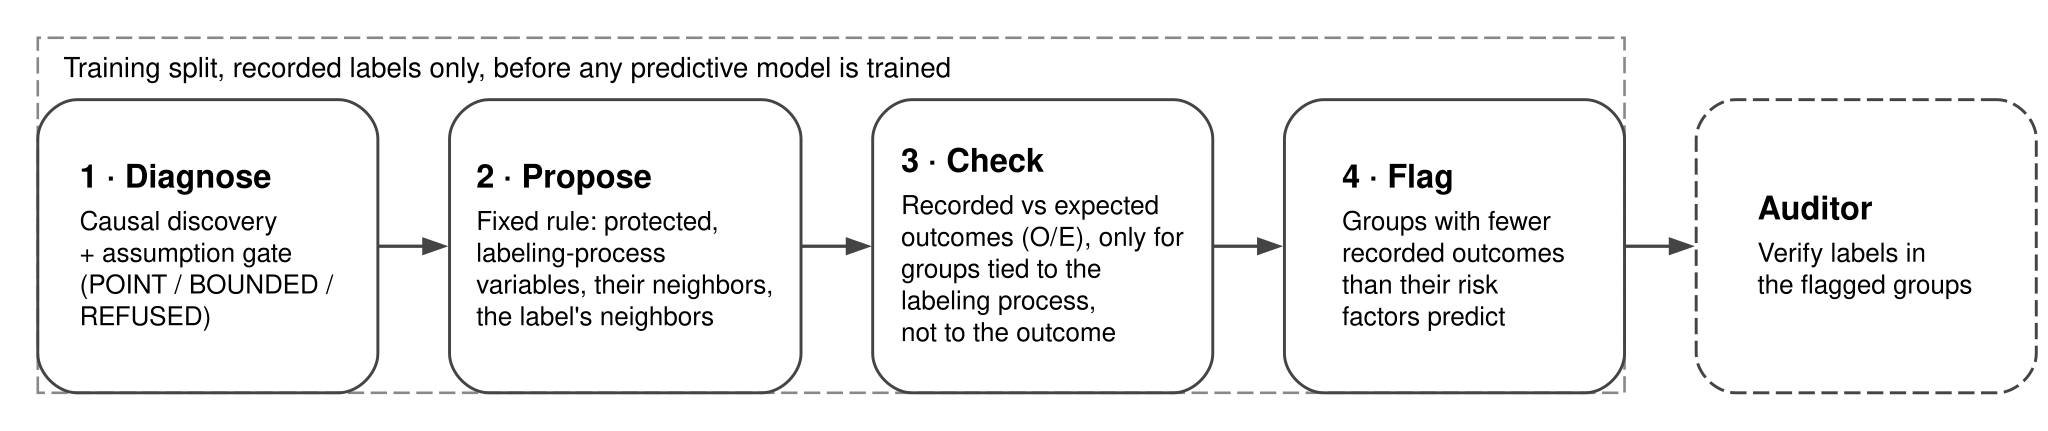

In [75]:
for d in (r"C:\Program Files\Graphviz\bin", r"C:\Program Files (x86)\Graphviz\bin"):
    if os.path.isdir(d) and d not in os.environ["PATH"]:
        os.environ["PATH"] += os.pathsep + d
import graphviz
GV_FONT = "Helvetica"

def render_gv(g, stem):
    (OUT / f"{stem}.pdf").write_bytes(g.pipe(format="pdf"))
    g.attr(dpi="300")
    (OUT / f"{stem}.png").write_bytes(g.pipe(format="png"))
    print("saved", stem, "(.pdf, .png) in", OUT)

def box(title, lines):
    body = '<BR ALIGN="LEFT"/>'.join(lines) + '<BR ALIGN="LEFT"/>'
    return (f'<<TABLE BORDER="0" CELLPADDING="1" CELLSPACING="0"><TR><TD ALIGN="LEFT"><B>{title}</B></TD></TR>'
            f'<TR><TD ALIGN="LEFT"><FONT POINT-SIZE="8.5">{body}</FONT></TD></TR></TABLE>>')

g = graphviz.Digraph("pipeline", engine="dot")
g.attr(rankdir="LR", nodesep="0.25", ranksep="0.3", pad="0.05", margin="0", bgcolor="white",
       fontname=GV_FONT, size="7,2.2")
g.attr("node", shape="box", style="rounded", fontname=GV_FONT, fontsize="10", margin="0.10,0.06",
       penwidth="0.9", color="#444444", width="1.45", height="1.25")
g.attr("edge", arrowsize="0.6", penwidth="1.0", color="#444444")
with g.subgraph(name="cluster_pre") as c:
    c.attr(style="dashed", color="#888888", penwidth="0.8", fontname=GV_FONT, fontsize="8.5", labeljust="l",
           label="Training split, recorded labels only, before any predictive model is trained")
    c.node("d", box("1 · Diagnose", ["Causal discovery", "+ assumption gate", "(POINT / BOUNDED /", "REFUSED)"]))
    c.node("c", box("2 · Propose", ["Fixed rule: protected,", "labeling-process", "variables, their neighbors,",
                                       "the label's neighbors"]))
    c.node("k", box("3 · Check", ["Recorded vs expected", "outcomes (O/E), only for", "groups tied to the", "labeling process,", "not to the outcome"]))
    c.node("f", box("4 · Flag", ["Groups with fewer", "recorded outcomes", "than their risk", "factors predict"]))
g.node("v", box("Auditor", ["Verify labels in", "the flagged groups"]), style="rounded,dashed")
g.edges([("d", "c"), ("c", "k"), ("k", "f"), ("f", "v")])
render_gv(g, "pipeline_discovery")
g

**How to read it.** Steps 1-4 (inside the dashed box) use only the training data's recorded labels and need
no trained model; that is the "before training" claim. The output is a short list of groups to verify;
the verification itself (dashed box) is outside the paper.

## 3. Figure 2 — what Stage 0 found around the label and the labeling-process variable
Shows only the stable edges (in at least 80% of bootstraps) that touch the label or the labeling-process variable.
Both gates are BOUNDED, so the method uses edges without trusting their direction; they are drawn
without arrowheads for that reason.


(process:12876): Pango-WARNING **: 15:56:33.148: couldn't load font "Helvetica Bold Not-Rotated 9", falling back to "Sans Bold Not-Rotated 9", expect ugly output.

(process:23916): Pango-WARNING **: 15:56:33.462: couldn't load font "Helvetica Bold Not-Rotated 9", falling back to "Sans Bold Not-Rotated 9", expect ugly output.


saved stage0_dag_nhanes (.pdf, .png) in D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\figures\paper_disc
18 variables, 24 stable edges



(process:836): Pango-WARNING **: 15:56:33.830: couldn't load font "Helvetica Bold Not-Rotated 9", falling back to "Sans Bold Not-Rotated 9", expect ugly output.


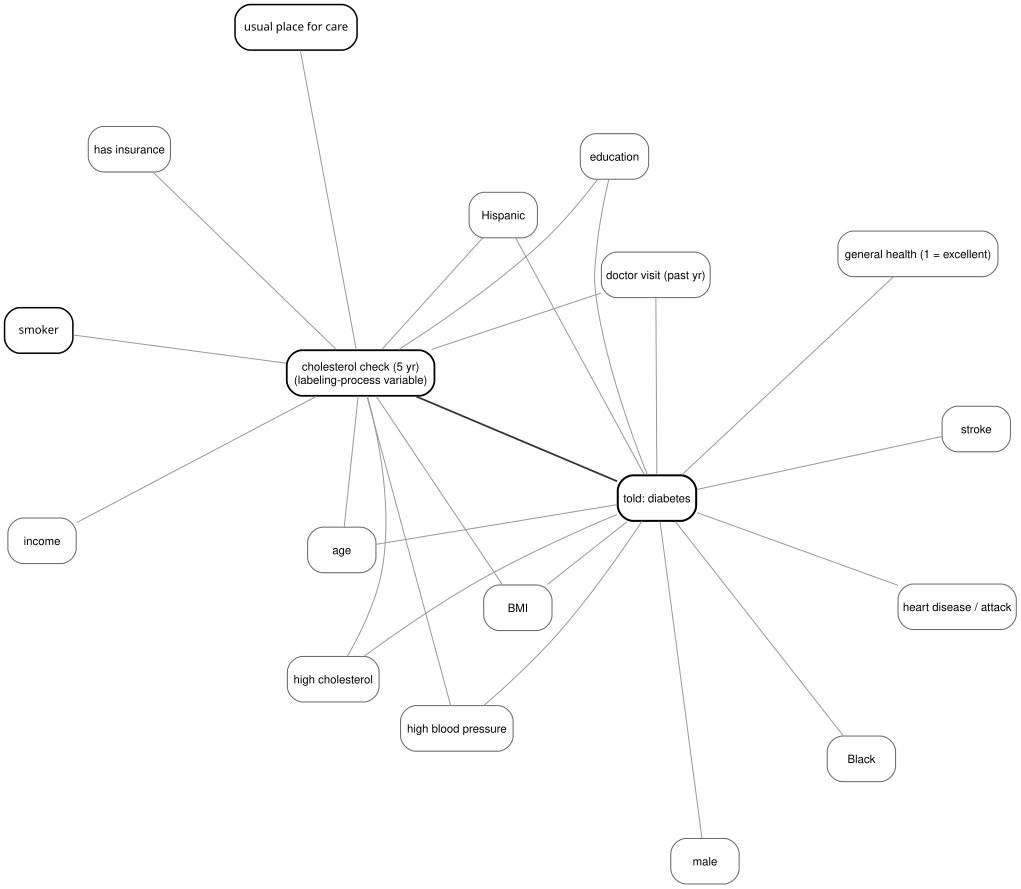

In [76]:
EDGE_P = 0.80
def draw_neighborhood(edges, label, recording, flagged_attrs, gate, stem):
    P = edges.groupby(["from", "to"])["prob_adjacent"].max()
    pairs = {}
    for (a, b), pr in P.items():
        if pr >= EDGE_P and (label in (a, b) or recording in (a, b)):
            key = tuple(sorted((a, b)))
            pairs[key] = max(pr, pairs.get(key, 0))
    nodes = sorted({n for k in pairs for n in k})
    g = graphviz.Graph(stem, engine="neato") if gate != "POINT" else graphviz.Digraph(stem, engine="neato")
    g.attr(overlap="false", splines="true", sep="+6", bgcolor="white", pad="0.05", size="3.4,3.0")
    g.attr("node", shape="box", style="rounded", fontname=GV_FONT, fontsize="9", margin="0.05,0.02",
           penwidth="0.8", color="#666666")
    g.attr("edge", color="#888888", penwidth="0.8")
    for n in nodes:
        if n == label:
            g.node(n, VAR.get(n, n), penwidth="1.6", color="#000000", style="rounded,bold")
        elif n == recording:
            g.node(n, VAR.get(n, n) + "\\n(labeling-process variable)", penwidth="1.4", color="#000000")
        elif n in flagged_attrs:
            g.node(n, VAR.get(n, n), fontname=GV_FONT + " Bold", color="#000000", penwidth="1.2")
        else:
            g.node(n, VAR.get(n, n))
    for (a, b), pr in pairs.items():
        both = (label in (a, b)) and (recording in (a, b))
        g.edge(a, b, penwidth="1.4" if both else "0.8", color="#333333" if both else "#999999")
    render_gv(g, stem)
    print(f"{len(nodes)} variables, {len(pairs)} stable edges")
    return g

nh_flag_attrs = {gr.split()[0] for gr in nh_oe.loc[nh_oe.flag_under_recorded, "group"]}
cdc_flag_attrs = {gr.split()[0] for gr in cdc_oe.loc[cdc_oe.flag_under_recorded, "group"]}
gn = draw_neighborhood(nh_edges, "diabetes_recorded", "CholCheck", nh_flag_attrs, nh_gate["rung"], "stage0_dag_nhanes")
gn


(process:32960): Pango-WARNING **: 15:56:34.258: couldn't load font "Helvetica Bold Not-Rotated 9", falling back to "Sans Bold Not-Rotated 9", expect ugly output.

(process:9596): Pango-WARNING **: 15:56:34.586: couldn't load font "Helvetica Bold Not-Rotated 9", falling back to "Sans Bold Not-Rotated 9", expect ugly output.


saved stage0_dag_cdc (.pdf, .png) in D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\figures\paper_disc
14 variables, 19 stable edges



(process:2552): Pango-WARNING **: 15:56:34.946: couldn't load font "Helvetica Bold Not-Rotated 9", falling back to "Sans Bold Not-Rotated 9", expect ugly output.


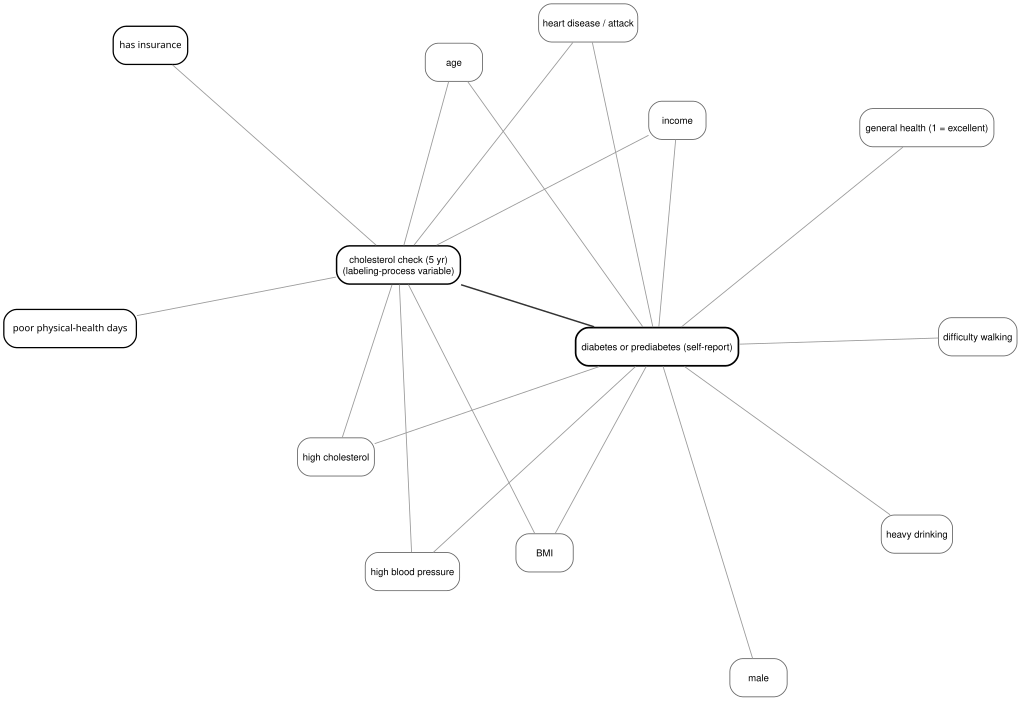

In [77]:
gc = draw_neighborhood(cdc_edges, "diabetes_any", "CholCheck", cdc_flag_attrs, cdc_gate["rung"], "stage0_dag_cdc")
gc

**How to read it.** Each line is an edge Stage 0 found in at least 80% of its bootstrap resamples. The bold
box is the label; the boxed "labeling-process variable" is the cholesterol check. Every variable shown is joined to
the label, to the cholesterol check, or both; those variables become the candidate groups (Section 4.2 of the
paper). Bold-text boxes are the variables whose groups the check flagged. The darker line between the label and
the cholesterol check is the labeling-process edge. Things to check against the tables: the flagged variables should
be joined to the cholesterol check, and *not* to the label (that is what makes the check valid).

## 4. Figure 3 — the main result: whose short list points to the missed diagnoses?
One row per method. Dot = the average missed-diagnosis ratio of the method's three groups (held-out NHANES
adults); line = 95% bootstrap interval. Dashed line at 1 = the same rate as everyone else.

saved shortlist_nhanes (.pdf, .png) in D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\figures\paper_disc


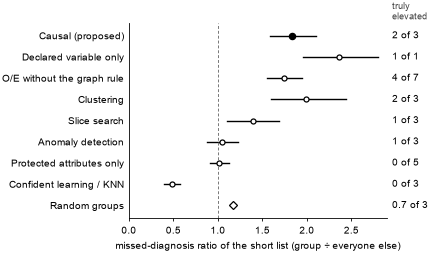

,name,groups,m,elev_n,mean_missed_ratio,lo,hi
8,Causal (proposed),CholCheck == 0; RoutineCare == 0; Smoker == 1,3,2,1.83,1.59,2.10
7,Declared variable only,CholCheck == 0,1,1,2.36,1.96,2.80
6,O/E without the graph rule,CholCheck == 0; RoutineCare == 0; Smoker == 1;...,7,4,1.74,1.55,1.95
5,Clustering,cluster 2; cluster 4; cluster 9,3,2,1.99,1.60,2.44
4,Slice search,GenHlth <= 2; Age <= 32; GenHlth <= 2 & Income...,3,1,1.40,1.10,1.69
3,Anomaly detection,Stroke == 1; HeartDiseaseorAttack == 1; Routin...,3,1,1.04,0.88,1.23
2,Protected attributes only,Sex == 1; Age <= 32; Age >= 67; race_black == ...,5,0,1.01,0.91,1.13
1,Confident learning / KNN,HeartDiseaseorAttack == 1; Stroke == 1; GenHlt...,3,0,0.49,0.39,0.58
0,Random groups,-,3,1,1.17,NaN,NaN


In [78]:
def lohi(s):
    if not isinstance(s, str):
        return np.nan, np.nan
    a, b = re.split(r"\s*(?:-|to)\s*(?=[\d+-])", s.strip(), maxsplit=1)
    return float(a), float(b)

NAME = {"causal (proposed): O/E flags": "Causal (proposed)", "slice search": "Slice search",
        "confident learning": "Confident learning", "KNN disagreement": "KNN label disagreement",
        "anomaly detection": "Anomaly detection", "random (mean of 200)": "Random groups",
        # rows from notebook 08, section 10 (added Nov 12, 2026)
        "ablation: declared variable only": "Declared variable only",
        "ablation: O/E without the graph rule": "O/E without the graph rule",
        "clustering (top m)": "Clustering", "protected only (all its groups)": "Protected attributes only"}
sh = nh_short.copy()
# the extra short lists: same scoring and the same bootstrap resamples as the rows above (notebook 08, section 10)
ex = read("08_ground_truth_shortlist_extra.csv")
ex = ex[ex["list"] != "causal (proposed): O/E flags"].rename(columns={"list": "method"})
ex["share_truly_elevated"] = ex.truly_elevated / ex.m
sh = pd.concat([sh, ex[["method", "m", "groups", "share_truly_elevated", "mean_missed_ratio", "ratio_ci"]]], ignore_index=True)
sh["name"] = sh.method.map(NAME)
sh[["lo", "hi"]] = [lohi(s) for s in sh.ratio_ci]
sh["elev_n"] = (sh.share_truly_elevated * sh.m).round().astype(int)
# confident learning and KNN chose the same three groups: show them on one row
same = sh[sh.method.isin(["confident learning", "KNN disagreement"])]
if len(same) == 2 and same.groups.nunique() == 1:
    sh.loc[sh.method == "confident learning", "name"] = "Confident learning / KNN"
    sh = sh[sh.method != "KNN disagreement"]
# row order, top to bottom: the method, its two ablations, then the comparison methods
ORDER = ["Causal (proposed)", "Declared variable only", "O/E without the graph rule", "Clustering", "Slice search",
         "Anomaly detection", "Protected attributes only", "Confident learning / KNN", "Confident learning",
         "KNN label disagreement", "Random groups"]
sh["order"] = sh.name.map({n: i for i, n in enumerate(ORDER)})
sh = sh.sort_values("order", ascending=False).reset_index(drop=True)     # plotted bottom to top, so the method is on top

fig, ax = plt.subplots(figsize=(COL_W, 0.42 + 0.235 * len(sh)))
y = np.arange(len(sh))
for i, r in sh.iterrows():
    is_c = r.method.startswith("causal")
    if np.isfinite(r.lo):
        ax.plot([r.lo, r.hi], [i, i], color="black", lw=1.0)
    ax.plot(r.mean_missed_ratio, i, marker="o" if np.isfinite(r.lo) else "D",
            ms=4.5 if is_c else 3.6, color="black", mfc="black" if is_c else "white", mew=0.9, zorder=3)
    lab = f"{r.elev_n} of {int(r.m)}" if not r.method.startswith("random") else f"{r.share_truly_elevated * r.m:.1f} of {int(r.m)}"
    ax.text(1.02, i, lab, transform=ax.get_yaxis_transform(), va="center", fontsize=7)
ax.text(1.02, len(sh) - 0.35, "truly\nelevated", transform=ax.get_yaxis_transform(), va="bottom", fontsize=6.5, color="#444444")
ax.axvline(1, color="#777777", lw=0.7, ls=(0, (3, 2)))
ax.set_yticks(y, sh.name)
ax.set_ylim(-0.6, len(sh) - 0.4)
ax.set_xlabel("missed-diagnosis ratio of the short list (group ÷ everyone else)")
ax.set_xlim(0, max(2.4, sh.hi.max() + 0.1))
ax.tick_params(axis="y", length=0)
savefig(fig, "shortlist_nhanes")
plt.show()
sh[["name", "groups", "m", "elev_n", "mean_missed_ratio", "lo", "hi"]].iloc[::-1].round(2)

**How to read it.** Read across a row. A dot at 2 means the people with diabetes in that method's three
groups were, on average, twice as likely to have *never been told* as people with diabetes elsewhere. Right of
the dashed line = the method points toward missed diagnoses; left = away from them. The numbers on the right
count how many of the three groups are significantly elevated on their own. Random groups have no interval
because they are an average of 200 draws. Things to check: the causal row should match the shortlist CSV
(1.83, 1.59-2.10); confident learning / KNN sit left of 1 because they chose stroke, heart disease and poor
health.

## 5. Table 2 — the answer key (NHANES, held-out adults)

In [79]:
key = nh_uni[nh_uni.p_holm < 0.05].sort_values("missed_ratio", ascending=False)
rows = []
for r in key.itertuples():
    rows.append(f"{tname(r.group)} & {r.true_pos:,} & {r.missed:,} & {100 * r.missed_share_group:.0f}\\% & "
                f"{100 * r.missed_share_rest:.0f}\\% & {r.missed_ratio:.1f}$\\times$ \\\\")
tex = ("{\\setlength{\\tabcolsep}{3.5pt}\n\\begin{tabular}{@{}lrrrrr@{}}\n\\toprule\n"
       "Group & \\shortstack[r]{With\\\\diabetes} & \\shortstack[r]{Never\\\\told} & \\shortstack[r]{Missed\\\\share} & "
       "\\shortstack[r]{Everyone\\\\else} & Ratio \\\\\n\\midrule\n" + "\n".join(rows) + "\n\\bottomrule\n\\end{tabular}}\n")
(OUT / "tab_answer_key.tex").write_text(tex, encoding="utf-8")
print(tex)
key[["group", "true_pos", "missed", "missed_share_group", "missed_share_rest", "missed_ratio", "p_holm"]].round(3)

{\setlength{\tabcolsep}{3.5pt}
\begin{tabular}{@{}lrrrrr@{}}
\toprule
Group & \shortstack[r]{With\\diabetes} & \shortstack[r]{Never\\told} & \shortstack[r]{Missed\\share} & \shortstack[r]{Everyone\\else} & Ratio \\
\midrule
No doctor visit, past year & 142 & 83 & 58\% & 18\% & 3.2$\times$ \\
No cholesterol check, 5 yr & 216 & 94 & 44\% & 18\% & 2.4$\times$ \\
No usual place for care & 138 & 61 & 44\% & 19\% & 2.3$\times$ \\
Excellent/very good health & 338 & 106 & 31\% & 19\% & 1.6$\times$ \\
Uninsured & 298 & 84 & 28\% & 20\% & 1.4$\times$ \\
\bottomrule
\end{tabular}}



,group,true_pos,missed,missed_share_group,missed_share_rest,missed_ratio,p_holm
0,VisitedDoctor == 0,142,83,0.585,0.183,3.198,0.000
1,CholCheck == 0,216,94,0.435,0.184,2.362,0.000
2,RoutineCare == 0,138,61,0.442,0.194,2.276,0.000
3,GenHlth <= 2,338,106,0.314,0.191,1.646,0.000
4,AnyHealthcare == 0,298,84,0.282,0.199,1.417,0.019


**How to read it.** Each row is a group whose people with diabetes (blood test or told) were significantly
more likely to have never been told (Fisher test, Holm-corrected across all candidate single-attribute groups).
"Missed share" is that group's rate; "Everyone else" is the rate outside the group; "Ratio" divides the two.
This table is the ground truth the methods are scored against.

## 6. Q3 table — the pre-training check against the truth (NHANES)
Top block: the groups where the graph makes the check valid. Bottom block: groups the graph rules out, to show
what the check would have said there (it misleads for BMI and age; it would have caught "no doctor visit").

In [80]:
t = nh_oe.merge(nh_gt[nh_gt.method == "causal (proposed)"][["group", "missed_ratio", "elevated"]], on="group")
def row(r, ruled_out=False):
    flag = "--" if ruled_out else ("yes" if r.flag_under_recorded else "")
    el = "yes" if r.elevated else ""
    return (f"{tname(r.group)} & {r.obs_over_exp:.2f} ({r.ci_low:.2f}--{r.ci_high:.2f}) & {flag} & "
            f"{r.missed_ratio:.2f} & {el} \\\\")
valid = t[t.valid].sort_values("obs_over_exp")
ruled = t[~t.valid & t.group.isin(["VisitedDoctor == 0", "GenHlth <= 2", "BMI <= 23.56", "Age <= 32"])].sort_values("obs_over_exp")
tex = ("{\\setlength{\\tabcolsep}{3.5pt}\n\\begin{tabular}{@{}lllll@{}}\n\\toprule\n"
       "Group & O/E (95\\% CI) & Flag & \\shortstack[l]{True\\\\missed\\\\ratio} & Elev. \\\\\n\\midrule\n"
       "\\multicolumn{5}{@{}l}{\\emph{Check valid (tied to the labeling process only)}} \\\\\n" + "\n".join(row(r) for r in valid.itertuples()) +
       "\n\\midrule\n\\multicolumn{5}{@{}l}{\\emph{Ruled out by the graph (edge into the label)}} \\\\\n" +
       "\n".join(row(r, ruled_out=True) for r in ruled.itertuples()) +
       "\n\\bottomrule\n\\end{tabular}}\n")
(OUT / "tab_nhanes_check.tex").write_text(tex, encoding="utf-8")
print(tex)
t[["group", "valid", "obs_over_exp", "ci_low", "ci_high", "flag_under_recorded", "missed_ratio", "elevated"]].round(3)

{\setlength{\tabcolsep}{3.5pt}
\begin{tabular}{@{}lllll@{}}
\toprule
Group & O/E (95\% CI) & Flag & \shortstack[l]{True\\missed\\ratio} & Elev. \\
\midrule
\multicolumn{5}{@{}l}{\emph{Check valid (tied to the labeling process only)}} \\
No cholesterol check, 5 yr & 0.73 (0.63--0.83) & yes & 2.36 & yes \\
No usual place for care & 0.74 (0.60--0.90) & yes & 2.28 & yes \\
Smoker & 0.87 (0.83--0.93) & yes & 0.86 &  \\
Income ratio $\ge$ 4.8 & 0.94 (0.84--1.05) &  & 1.02 &  \\
Income ratio $\le$ 0.97 & 1.01 (0.93--1.10) &  & 1.04 &  \\
Uninsured & 1.11 (0.98--1.24) &  & 1.42 & yes \\
\midrule
\multicolumn{5}{@{}l}{\emph{Ruled out by the graph (edge into the label)}} \\
Age $\le$ 32 & 0.22 (0.16--0.29) & -- & 1.07 &  \\
No doctor visit, past year & 0.37 (0.28--0.46) & -- & 3.20 & yes \\
Excellent/very good health & 0.42 (0.37--0.47) & -- & 1.65 & yes \\
BMI $\le$ 23.56 & 0.58 (0.50--0.67) & -- & 0.79 &  \\
\bottomrule
\end{tabular}}



,group,valid,obs_over_exp,ci_low,ci_high,flag_under_recorded,missed_ratio,elevated
0,CholCheck == 0,True,0.726,0.629,0.834,True,2.362,True
1,RoutineCare == 0,True,0.739,0.603,0.897,True,2.276,True
2,Smoker == 1,True,0.875,0.826,0.926,True,0.862,False
3,Income >= 4.8,True,0.941,0.844,1.046,False,1.019,False
4,Income <= 0.97,True,1.008,0.926,1.096,False,1.038,False
5,AnyHealthcare == 0,True,1.105,0.984,1.238,False,1.417,True
6,Age <= 32,False,0.220,0.163,0.290,False,1.071,False
7,VisitedDoctor == 0,False,0.365,0.284,0.462,False,3.198,True
8,GenHlth <= 2,False,0.419,0.375,0.467,False,1.646,True
9,BMI <= 23.56,False,0.577,0.498,0.666,False,0.786,False


**How to read it.** O/E below 1 means fewer recorded diagnoses than the group's risk factors predict (computed
from training labels only, before training). "True missed ratio" comes from the blood test (held-out adults).
In the top block, the two groups with the lowest O/E are the two with the highest true missed ratio, and both
are elevated: the check points the right way where it is valid. Smoker is the false flag. In the bottom
block, O/E is low for every group, right or wrong (BMI and young age are *not* elevated): where the graph does not support it, the check cannot be trusted. "No doctor visit" is the honest miss: elevated, low O/E, but ruled out.

## 7. Table 3 — CDC: the same rule's flags, and how the other methods ranked those groups

In [81]:
b = cdc_blind.copy()
def rk(s):
    return s.replace("/", " / ") if isinstance(s, str) else "--"
rows = [f"{tname(r.group)} & {100 * r.share_train:.0f}\\% & {r.obs_over_exp:.2f} ({r.ci_low:.2f}--{r.ci_high:.2f}) & "
        f"{r.calib_ratio:.2f} & {rk(r.rank_in_slice)} & {rk(r.rank_in_confident)} & {rk(r.rank_in_knn)} & {rk(r.rank_in_anomaly)} \\\\"
        for r in b.sort_values("obs_over_exp").itertuples()]
tex = ("\\begin{tabular}{@{}lrlrrrrr@{}}\n\\toprule\n"
       " & & & \\shortstack[r]{Test-set\\\\pred./actual} & \\multicolumn{4}{c}{Rank given by} \\\\\n\\cmidrule(l){5-8}\n"
       "Group & Share & O/E (95\\% CI) & & Slice & CL & KNN & Anom. \\\\\n\\midrule\n" + "\n".join(rows) +
       "\n\\bottomrule\n\\end{tabular}\n")
(OUT / "tab_cdc_flags.tex").write_text(tex, encoding="utf-8")
print(tex)
b.round(3)

\begin{tabular}{@{}lrlrrrrr@{}}
\toprule
 & & & \shortstack[r]{Test-set\\pred./actual} & \multicolumn{4}{c}{Rank given by} \\
\cmidrule(l){5-8}
Group & Share & O/E (95\% CI) & & Slice & CL & KNN & Anom. \\
\midrule
No cholesterol check, 5 yr & 4\% & 0.39 (0.33--0.45) & 1.22 & 22 / 213 & 25 / 25 & 25 / 25 & 9 / 25 \\
Uninsured & 5\% & 0.90 (0.85--0.97) & 1.05 & 55 / 213 & 19 / 25 & 19 / 25 & 3 / 25 \\
5+ poor physical-health days & 21\% & 0.96 (0.94--0.99) & 1.02 & 157 / 213 & 5 / 25 & 6 / 25 & 6 / 25 \\
\bottomrule
\end{tabular}



,group,share_train,calib_ratio,recall_gap,confirmed_missed,confirmed_underpred,obs_over_exp,ci_low,ci_high,rank_in_slice,rank_in_confident,rank_in_knn,rank_in_anomaly
0,CholCheck == 0,0.037,1.218,0.252,True,False,0.387,0.328,0.455,22/213,25/25,25/25,9/25
1,AnyHealthcare == 0,0.049,1.049,0.076,False,False,0.905,0.846,0.967,55/213,19/25,19/25,3/25
2,PhysHlth >= 5,0.214,1.016,-0.290,False,False,0.965,0.944,0.986,157/213,5/25,6/25,6/25


**How to read it.** These are the groups the check could validly test on CDC (it flags the ones whose upper CI
is below 1). "Test-set pred./actual" near 1 means the trained model looks fine for the group on the test set,
so a post-training audit would not notice anything. The rank columns show where each other method placed the
same group in its own list ("25 / 25" = last of 25). The no-cholesterol-check group is flagged on both
datasets; confident learning and KNN rank it last.

## 7b. Table 4 — sensitivity analysis: the same rule with three causal-discovery algorithms
From notebook 10 (full size: every algorithm on the same discovery rows as DirectLiNGAM) and notebook 10b
(reduced size, 5,000 rows per resample, shown in the bottom block). DirectLiNGAM is the pre-specified analysis
(notebooks 06/08). "Plausible graph" is an objective check: does the algorithm link BMI **and** high blood
pressure to diabetes, two well-established risk factors? NHANES columns are scored against the blood-test truth
(held-out adults); CDC has no ground truth.

In [82]:
sens, sens_b = read("10_summary.csv"), read("10b_summary.csv")
nbr, nbr_b = read("10_neighbors.csv"), read("10b_neighbors.csv")
tr_full, tr_b = read("10_truth_shortlists.csv"), read("10b_truth_shortlists.csv")
SHORT = {"CholCheck == 0": r"no chol.\ check", "RoutineCare == 0": "no usual place", "Smoker == 1": "smoker",
         "AnyHealthcare == 0": "uninsured", "PhysHlth >= 6": r"poor phys.\ health", "PhysHlth >= 5": r"poor phys.\ health",
         "VisitedDoctor == 0": "no doctor visit",
         "Age <= 5": "youngest age", "Education >= 6": "college grad.", "HvyAlcoholConsump == 1": "heavy drinking",
         "Income >= 8": "highest income", "MentHlth >= 4": "poor mental health", "MentHlth >= 3": "poor mental health",
         "NoDocbcCost == 1": "couldn't afford doctor"}
def short(lst):
    if not isinstance(lst, str) or not lst.strip():
        return "--"
    return ", ".join(SHORT.get(g.strip(), tname(g.strip())) for g in lst.split(", "))
def plausible(nb_df, ds, alg):
    r = nb_df[(nb_df.dataset == ds) & (nb_df.algorithm == alg)].iloc[0]
    lab = {v.strip() for v in str(r.linked_to_label).split(",")}
    return "yes" if {"BMI", "HighBP"} <= lab else "no"
def truth_cell(tr, alg):
    if alg == "DirectLiNGAM":   # use notebook 08's numbers, so the paper quotes one value everywhere
        r = nh_short[nh_short.method == "causal (proposed): O/E flags"].iloc[0]
        lo, hi = lohi(r.ratio_ci)
        return f"{round(r.share_truly_elevated * r.m)} of {int(r.m)}", f"{r.mean_missed_ratio:.2f} ({lo:.2f}--{hi:.2f})"
    r = tr[tr.list == f"causal: {alg}"].iloc[0]
    if not r.m:
        return "--", "--"
    return f"{int(r.truly_elevated)} of {int(r.m)}", f"{r.mean_missed_ratio:.2f} ({r.ci_low:.2f}--{r.ci_high:.2f})"

ALGS = ["DirectLiNGAM", "PC-G2", "LiM"]
NAMEA = {"DirectLiNGAM": "DirectLiNGAM (pre-specified)", "PC-G2": "PC with G$^2$ test", "LiM": "LiM"}
def block(s, nb_df, tr, algs, rows_label):
    out, view = [], []
    for alg in algs:
        nh = s[(s.dataset == "nhanes") & (s.algorithm == alg)].iloc[0]
        cd = s[(s.dataset == "cdc") & (s.algorithm == alg)].iloc[0]
        te, mr = truth_cell(tr, alg)
        pl = f"{plausible(nb_df, 'nhanes', alg)} / {plausible(nb_df, 'cdc', alg)}"
        rows = "$\\le$20,000" if alg == "DirectLiNGAM" else rows_label
        out.append(f"{NAMEA[alg]} & {rows} & {pl} & {short(nh.flagged)} & {te} & {mr} & {short(cd.flagged)} \\\\")
        view.append({"algorithm": alg, "rows": rows.replace("$\\le$", "<="), "plausible (NH/CDC)": pl,
                     "NHANES flags": nh.flagged, "truly elevated": te, "missed ratio": mr, "CDC flags": cd.flagged})
    return out, view
full_rows, v1 = block(sens, nbr, tr_full, ALGS, "$\\le$20,000")
red_rows, v2 = block(sens_b, nbr_b, tr_b, ["PC-G2", "LiM"], "5,000")
tex = ("\\begin{tabular}{@{}lll>{\\raggedright\\arraybackslash}p{2.9cm}l>{\\raggedright\\arraybackslash}p{2.0cm}>{\\raggedright\\arraybackslash}p{3.2cm}@{}}\n\\toprule\n"
       " & Rows per & Plausible & \\multicolumn{3}{c}{NHANES (blood-test truth)} & CDC \\\\\n\\cmidrule(lr){4-6}\n"
       "Algorithm & resample & graph & Flagged groups & \\shortstack[l]{Truly\\\\elevated} & Missed ratio (95\\% CI) & Flagged groups \\\\\n\\midrule\n"
       + "\n".join(full_rows) +
       "\n\\midrule\n\\multicolumn{7}{@{}l}{\\emph{Reduced size (notebook 10b), run first; reported for completeness}} \\\\\n"
       + "\n".join(red_rows) + "\n\\bottomrule\n\\end{tabular}\n")
(OUT / "tab_sensitivity.tex").write_text(tex, encoding="utf-8")
print(tex)

# (needs \\usepackage{array} in the paper; main_discovery.tex already loads it)
# numbers for the text (merged into disc_macros.tex by section 8)
def runs_flagging(s, grp, ds=None):
    t = s if ds is None else s[s.dataset == ds]
    return int(sum(grp in str(f).split(", ") for f in t.flagged))
pc_nh = tr_full[tr_full.list == "causal: PC-G2"].iloc[0]; pcb_nh = tr_b[tr_b.list == "causal: PC-G2"].iloc[0]
SENS_M = {
    "DSsensRuns": f"{len(sens)}",
    "DSsensCholRuns": f"{runs_flagging(sens, 'CholCheck == 0')}",
    "DSsensInsRunsCDC": f"{runs_flagging(sens, 'AnyHealthcare == 0', 'cdc')}",
    "DSsensPCnhRatio": f"{pc_nh.mean_missed_ratio:.2f}", "DSsensPCnhLo": f"{pc_nh.ci_low:.2f}", "DSsensPCnhHi": f"{pc_nh.ci_high:.2f}",
    "DSsensPCbNhRatio": f"{pcb_nh.mean_missed_ratio:.2f}", "DSsensPCbNhElev": f"{int(pcb_nh.truly_elevated)}",
    "DSsensPCbNhM": f"{int(pcb_nh.m)}",
}
print(SENS_M)
pd.DataFrame(v1 + v2)

\begin{tabular}{@{}lll>{\raggedright\arraybackslash}p{2.9cm}l>{\raggedright\arraybackslash}p{2.0cm}>{\raggedright\arraybackslash}p{3.2cm}@{}}
\toprule
 & Rows per & Plausible & \multicolumn{3}{c}{NHANES (blood-test truth)} & CDC \\
\cmidrule(lr){4-6}
Algorithm & resample & graph & Flagged groups & \shortstack[l]{Truly\\elevated} & Missed ratio (95\% CI) & Flagged groups \\
\midrule
DirectLiNGAM (pre-specified) & $\le$20,000 & yes / yes & no chol.\ check, no usual place, smoker & 2 of 3 & 1.83 (1.59--2.10) & no chol.\ check, uninsured, poor phys.\ health \\
PC with G$^2$ test & $\le$20,000 & yes / yes & no chol.\ check & 1 of 1 & 2.36 (1.97--2.79) & no chol.\ check, uninsured \\
LiM & $\le$20,000 & no / no & no chol.\ check & 1 of 1 & 2.36 (1.97--2.79) & youngest age, no chol.\ check, college grad., heavy drinking \\
\midrule
\multicolumn{7}{@{}l}{\emph{Reduced size (notebook 10b), run first; reported for completeness}} \\
PC with G$^2$ test & 5,000 & yes / yes & no chol.\ check, no usu

,algorithm,rows,plausible (NH/CDC),NHANES flags,truly elevated,missed ratio,CDC flags
0,DirectLiNGAM,"<=20,000",yes / yes,"CholCheck == 0, RoutineCare == 0, Smoker == 1",2 of 3,1.83 (1.59--2.10),"CholCheck == 0, AnyHealthcare == 0, PhysHlth >= 5"
1,PC-G2,"<=20,000",yes / yes,CholCheck == 0,1 of 1,2.36 (1.97--2.79),"CholCheck == 0, AnyHealthcare == 0"
2,LiM,"<=20,000",no / no,CholCheck == 0,1 of 1,2.36 (1.97--2.79),"Age <= 5, CholCheck == 0, Education >= 6, HvyA..."
3,PC-G2,"5,000",yes / yes,"CholCheck == 0, RoutineCare == 0, VisitedDocto...",3 of 3,2.61 (2.25--3.00),CholCheck == 0
4,LiM,"5,000",no / no,CholCheck == 0,1 of 1,2.36 (1.97--2.79),"Age <= 5, CholCheck == 0, Education >= 6, HvyA..."


**How to read it.** One row per algorithm. Read across: which groups that algorithm's version of the rule
flags on each dataset, and for NHANES how many of them are truly elevated and their average missed-diagnosis
ratio. Things to check: "no chol. check" appears in every full-size row on both datasets (the robust finding);
"uninsured" appears on CDC for the two algorithms with a plausible graph; LiM's graph is not plausible (it does not
link BMI and high blood pressure to diabetes) and its CDC flags include youngest age and heavy drinking, the same
false-alarm types the Q3 table shows. The bottom block shows that at 5,000 rows per resample PC-G² gave a
different NHANES answer, so results beyond the robust core depend on sample size as well as algorithm.

## 8. Numbers for the paper (`disc_macros.tex`)
Every number the text quotes, as a LaTeX macro (`\DS...`). Use them in the prose instead of typing numbers.

In [83]:
M = {}
f2 = lambda x: f"{x:.2f}"
def c_row(method):
    return nh_short[nh_short.method == method].iloc[0]
cr = c_row("causal (proposed): O/E flags")
M["DSnNH"] = f"{len(nh_all):,}"; M["DSnHeld"] = f"{len(nh_held):,}"
M["DSmissedAll"] = f"{int(nh_all.missed.sum()):,}"
M["DSmissedPct"] = f"{100 * nh_all.missed.sum() / nh_all.diabetes_true.sum():.1f}"
M["DSmissedHeld"] = f"{int(nh_held.missed.sum()):,}"
M["DSnCDC"] = f"{sum(len(pd.read_csv(DATA / f'cdcfull_{p_}.csv')) for p_ in ('train', 'val', 'test')):,}"   # all three splits
M["DSnCDCtrain"] = f"{len(cdc_train):,}"
M["DSrateCDC"] = f"{100 * pd.concat([pd.read_csv(DATA / f'cdcfull_{p_}.csv') for p_ in ('train', 'val', 'test')]).diabetes_any.mean():.1f}"
M["DSgateNH"] = nh_gate["rung"]; M["DSgateCDC"] = cdc_gate["rung"]
M["DSbinNH"] = re.search(r"(\d+)%", nh_gate["reasons"][0]).group(1) if nh_gate["reasons"] else ""
M["DSbinCDC"] = re.search(r"(\d+)%", cdc_gate["reasons"][0]).group(1) if cdc_gate["reasons"] else ""
for key_, meth in [("Causal", "causal (proposed): O/E flags"), ("Slice", "slice search"),
                   ("CL", "confident learning"), ("Anom", "anomaly detection"), ("Rand", "random (mean of 200)")]:
    r = c_row(meth)
    M[f"DSratio{key_}"] = f2(r.mean_missed_ratio)
    lo, hi = lohi(r.ratio_ci)
    if np.isfinite(lo):
        M[f"DSratio{key_}Lo"], M[f"DSratio{key_}Hi"] = f2(lo), f2(hi)
    M[f"DSelev{key_}"] = f"{r.share_truly_elevated * r.m:.0f}" if key_ != "Rand" else f"{r.share_truly_elevated * r.m:.1f}"
    if key_ not in ("Causal", "Rand"):
        lo, hi = lohi(r.causal_minus_this_ratio_ci)
        M[f"DSdiff{key_}Lo"], M[f"DSdiff{key_}Hi"] = f2(lo), f2(hi)
        M[f"DSpBeat{key_}"] = f"{100 * r.share_boot_causal_higher:.0f}"
M["DSm"] = f"{int(cr.m)}"
M["DSnKey"] = f"{len(key)}"
for gq, k in [("VisitedDoctor == 0", "Visit"), ("CholCheck == 0", "Chol"), ("RoutineCare == 0", "Routine"),
              ("AnyHealthcare == 0", "Ins"), ("GenHlth <= 2", "Health")]:
    r = nh_uni[nh_uni.group == gq].iloc[0]
    M[f"DSkey{k}Ratio"] = f"{r.missed_ratio:.1f}"; M[f"DSkey{k}Share"] = f"{100 * r.missed_share_group:.0f}"
    M[f"DSkey{k}Rest"] = f"{100 * r.missed_share_rest:.0f}"
for df_, ds in [(nh_oe, "NH"), (cdc_oe, "CDC")]:
    for gq, k in [("CholCheck == 0", "Chol"), ("RoutineCare == 0", "Routine"), ("Smoker == 1", "Smoker"),
                  ("AnyHealthcare == 0", "Ins"), ("VisitedDoctor == 0", "Visit"), ("PhysHlth >= 6", "PhysHlth")]:
        r = df_[df_.group == gq]
        if len(r):
            r = r.iloc[0]
            M[f"DSoe{ds}{k}"] = f2(r.obs_over_exp); M[f"DSoe{ds}{k}Lo"] = f2(r.ci_low); M[f"DSoe{ds}{k}Hi"] = f2(r.ci_high)
M["DSnCandNH"] = f"{len(nh_oe)}"; M["DSnValidNH"] = f"{int(nh_oe.valid.sum())}"; M["DSnFlagNH"] = f"{int(nh_oe.flag_under_recorded.sum())}"
M["DSnCandCDC"] = f"{len(cdc_oe)}"; M["DSnValidCDC"] = f"{int(cdc_oe.valid.sum())}"; M["DSnFlagCDC"] = f"{int(cdc_oe.flag_under_recorded.sum())}"
M["DScalibNHChol"] = f2(nh_conf[(nh_conf.method == "causal (proposed)") & (nh_conf.group == "CholCheck == 0")].calib_ratio.iloc[0])
M["DScalibCDCChol"] = f2(cdc_blind[cdc_blind.group == "CholCheck == 0"].calib_ratio.iloc[0])
M["DSrankCLCholCDC"] = str(cdc_blind[cdc_blind.group == "CholCheck == 0"].rank_in_confident.iloc[0])
for df_, ds in [(nh_score, "NH"), (cdc_score, "CDC")]:
    s_ = df_.set_index("method")
    M[f"DSconfSlice{ds}"] = f"{s_.loc['slice search', 'confirmed_missed']:.0f}"
    M[f"DSconfCausal{ds}"] = f"{s_.loc['causal (proposed)', 'confirmed_missed']:.0f}"
    M[f"DSconfRand{ds}"] = f"{s_.loc['random (mean of 20)', 'confirmed_missed']:.1f}"
    M[f"DSK{ds}"] = f"{s_.loc['causal (proposed)', 'K']:.0f}"
    M[f"DSunderpred{ds}"] = f"{df_.confirmed_underpred.sum():.0f}"

# Q3 numbers: does O/E point the right way where valid, and mislead where ruled out? (t = section 6 table)
from scipy.stats import spearmanr
_v = t[t.valid]
M["DSspearmanNH"] = f"${spearmanr(_v.obs_over_exp, _v.missed_ratio)[0]:.2f}$"   # printed in math mode (minus sign)
M["DSnValidSpearmanNH"] = f"{len(_v)}"
for gq, k in [("BMI <= 23.56", "BMI"), ("Age <= 32", "Young"), ("VisitedDoctor == 0", "Visit"), ("GenHlth <= 2", "Health")]:
    _r = t[t.group == gq]
    if len(_r):
        M[f"DSmissNH{k}"] = f"{_r.missed_ratio.iloc[0]:.2f}"
        M[f"DSoeNH{k}"] = f"{_r.obs_over_exp.iloc[0]:.2f}"
_ph = cdc_oe[cdc_oe.group.str.startswith("PhysHlth >=")]
if len(_ph):
    M["DSoeCDCPhysHlth"] = f2(_ph.obs_over_exp.iloc[0]); M["DSoeCDCPhysHlthLo"] = f2(_ph.ci_low.iloc[0])
    M["DSoeCDCPhysHlthHi"] = f2(_ph.ci_high.iloc[0])
    M["DSphysCutCDC"] = _ph.group.iloc[0].split(">=")[1].strip()            # days; use in the text ("X or more days")
_b = cdc_oe[cdc_oe.group.str.startswith("BMI <=")]
if len(_b):
    M["DSoeCDCBMI"] = f"{_b.obs_over_exp.iloc[0]:.2f}"
    M["DSbmiCutCDC"] = _b.group.iloc[0].split("<=")[1].strip()
# ---- numbers from notebook 08, section 10 (added Nov 12, 2026): extra short lists, per-record rates, recall gaps ----
def signed(x):                                   # negative numbers are printed in math mode, like the Spearman macro
    return f"${x:.2f}$" if x < 0 else f"{x:.2f}"
_x = read("08_ground_truth_shortlist_extra.csv").set_index("list")
_gt = read("08_ground_truth.csv")
for _name, _k in [("clustering (top m)", "Clu"), ("protected only (all its groups)", "Prot"),
                  ("ablation: declared variable only", "Decl"), ("ablation: O/E without the graph rule", "NoRule")]:
    _r = _x.loc[_name]
    _lo, _hi = lohi(_r.ratio_ci)
    M[f"DSratio{_k}"] = f2(_r.mean_missed_ratio); M[f"DSratio{_k}Lo"] = f2(_lo); M[f"DSratio{_k}Hi"] = f2(_hi)
    M[f"DSelev{_k}"] = f"{int(_r.truly_elevated)}"; M[f"DSm{_k}"] = f"{int(_r.m)}"
    M[f"DSmissedIn{_k}"] = f"{int(_r.missed_cases_in_list)}"
    _d = [float(v) for v in str(_r.causal_minus_this_ratio_ci).split(" to ")]
    M[f"DSdiff{_k}Lo"] = signed(_d[0]); M[f"DSdiff{_k}Hi"] = signed(_d[1])
    M[f"DSpBeat{_k}"] = f"{100 * _r.share_boot_causal_higher:.0f}"
M["DSmissedInCausal"] = f"{int(_x.loc['causal (proposed): O/E flags', 'missed_cases_in_list'])}"

def _elev_cases(method, groups):                 # true cases in the truly elevated groups of a short list, e.g. "216 and 138"
    g = _gt[(_gt.method == method) & _gt.group.isin(groups)].drop_duplicates("group").set_index("group").loc[groups]
    e = g[g.p_truth < 0.05 / len(groups)]
    return list(e.index), " and ".join(str(int(v)) for v in e.true_pos)
_clu_groups = _x.loc["clustering (top m)", "groups"].split("; ")
_cau_groups = _x.loc["causal (proposed): O/E flags", "groups"].split("; ")
_clu_elev, M["DScluElevCases"] = _elev_cases("clustering", _clu_groups)
_, M["DScausalElevCases"] = _elev_cases("causal (proposed)", _cau_groups)
_cp = read("08_cluster_profiles.csv").set_index("cluster").loc[_clu_elev]
M["DScluNoRoutinePct"] = f"{100 * _cp['share in [RoutineCare == 0]'].mean():.0f}"   # elevated clusters: share with no usual place for care
M["DScluNoCholPct"] = f"{100 * _cp['share in [CholCheck == 0]'].mean():.0f}"         # ... and with no cholesterol check
for _g, _k in [("CholCheck == 0", "Chol"), ("RoutineCare == 0", "Routine"), ("Smoker == 1", "Smoker")]:
    _r = _gt[(_gt.method == "causal (proposed)") & (_gt.group == _g)].iloc[0]
    M[f"DSmissNH{_k}"] = f2(_r.missed_ratio)                                         # missed ratio to two decimals

_pr = read("08_per_record_rates.csv").set_index("group")
M["DSprAll"] = f"{_pr.loc['all held-out adults', 'missed_per_100_recorded_no']:.1f}"
M["DSprevAll"] = f"{_pr.loc['all held-out adults', 'true_rate_pct']:.1f}"
for _g, _k in [("CholCheck == 0", "Chol"), ("RoutineCare == 0", "Routine"), ("VisitedDoctor == 0", "Visit"),
               ("GenHlth <= 2", "Health"), ("AnyHealthcare == 0", "Ins")]:
    M[f"DSpr{_k}"] = f"{_pr.loc[_g, 'missed_per_100_recorded_no']:.1f}"
    M[f"DSpr{_k}Rest"] = f"{_pr.loc[_g, 'rest_missed_per_100_recorded_no']:.1f}"
    M[f"DSprev{_k}"] = f"{_pr.loc[_g, 'true_rate_pct']:.1f}"

_nb, _cb = read("08_blind_spot.csv").set_index("group"), read("06_blind_spot.csv").set_index("group")
M["DSrecallGapNHChol"] = f2(_nb.loc["CholCheck == 0", "recall_gap"])
M["DSrecallGapNHRoutine"] = f2(_nb.loc["RoutineCare == 0", "recall_gap"])
M["DSrecallGapCDCChol"] = f2(_cb.loc["CholCheck == 0", "recall_gap"])

# ---- Section 5 numbers (added Nov 12, 2026): dataset rates and the identical-rows check on the raw CDC file ----
M["DSrateNH"] = f"{100 * nh_all.diabetes_recorded.mean():.1f}"            # NHANES recorded rate, %
M["DStrueRateNH"] = f"{100 * nh_all.diabetes_true.mean():.1f}"            # NHANES true rate (told or HbA1c >= 6.5%), %
_raw = pd.read_csv(DATA / "cdc_diabetes_raw.csv")
_twin = _raw.duplicated(keep=False)                                       # rows whose answers are identical to another row's
M["DSposCDC"] = f"{int((_raw.Diabetes_binary > 0).sum()):,}"              # recorded positives in the CDC file
M["DSidenticalDropped"] = f"{len(_raw) - len(_raw.drop_duplicates()):,}"  # rows the earlier analysis removed
M["DSidenticalRate"] = f"{100 * (_raw.Diabetes_binary[_twin] > 0).mean():.1f}"    # recorded rate among rows with a twin, %
M["DSuniqueRate"] = f"{100 * (_raw.Diabetes_binary[~_twin] > 0).mean():.1f}"      # recorded rate among unique rows, %

M.update(globals().get("SENS_M", {}))       # sensitivity numbers from section 7b
bad = [k for k in M if not re.fullmatch(r"[A-Za-z]+", k)]
assert not bad, f"macro names must be letters only: {bad}"
lines = ["% generated by 09_paper_figures_discovery.ipynb -- do not edit by hand"]
lines += [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in M.items()]
(OUT / "disc_macros.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"wrote {OUT / 'disc_macros.tex'} ({len(M)} macros)")
pd.Series(M).to_frame("value")

wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\figures\paper_disc\disc_macros.tex (190 macros)


,value
DSnNH,"30,773"
DSnHeld,"12,310"
DSmissedAll,979
DSmissedPct,19.9
DSmissedHeld,423
...,...
DSsensPCnhLo,1.97
DSsensPCnhHi,2.79
DSsensPCbNhRatio,2.61
DSsensPCbNhElev,3


## 9. Copy to the paper folder (only when you are happy with sections 2-8)
Set `EXPORT_TO_PAPER = True` and run this cell. It copies the PDFs to `label_integrity_paper/figures/` and the
three tables and `disc_macros.tex` to `label_integrity_paper/`. Nothing else in the paper folder is touched.

In [84]:
EXPORT_TO_PAPER = True
PAPER = ROOT.parents[2] / "TRUST 2027 Papers" / "label_integrity_paper"
if EXPORT_TO_PAPER:
    (PAPER / "figures").mkdir(parents=True, exist_ok=True)
    for stem in ["pipeline_discovery", "stage0_dag_nhanes", "stage0_dag_cdc", "shortlist_nhanes"]:
        shutil.copy2(OUT / f"{stem}.pdf", PAPER / "figures" / f"{stem}.pdf")
    for f in ["tab_answer_key.tex", "tab_nhanes_check.tex", "tab_cdc_flags.tex", "tab_sensitivity.tex", "disc_macros.tex"]:
        shutil.copy2(OUT / f, PAPER / f)
    print("copied to", PAPER)
else:
    print("not exported yet; look at the figures in", OUT, "then set EXPORT_TO_PAPER = True")

copied to D:\Documents\PhD_program\DISSERTATION_RELATED\TRUST 2027 Papers\label_integrity_paper
